---
title: "circling back"
execute:
  freeze: auto  # re-render only when source changes
format:
  html:
    code-fold: true
    code-summary: "Show the code"
---

We opened this part with three questions about sea surface temperature (see [motivation](motivation.qmd)):

* disconsidering the expected annual cycle, how fast is the ocean warming up?
* what is a *typical* annual oscillation in temperature?
* how can I model processes such as this, where there are both a clear trend and a seasonal component?

We now have the tools to answer them. Let's start by loading the most recent data and decomposing it exactly as we did in [seasonal decomposition from scratch](seasonal-decomposition-from-scratch.ipynb).

In [1]:
#| code-summary: "import stuff"
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import seaborn as sns
sns.set_theme(style="ticks", font_scale=1.5)
import urllib.request
import json

In [2]:
#| code-summary: "download data"
def download_sst(region):
    """download daily SST from Climate Reanalyzer, return a dataframe with an 'sst' column"""
    url = f"https://climatereanalyzer.org/clim/sst_daily/json_2clim/oisst2.1_{region}_sst_day.json"
    with urllib.request.urlopen(url, timeout=30) as response:
        data = json.load(response)
    # data is a list with one entry per year, each holding 366 daily values starting on Jan 1
    pieces = []
    for entry in data:
        if not entry['name'].isdigit():  # skip "Preliminary", "1982-2010" climatology, etc.
            continue
        year = int(entry['name'])
        dates = pd.date_range(f"{year}-01-01", f"{year}-12-31", freq="D")  # 365 or 366 days
        pieces.append(pd.Series(entry['data'][:len(dates)], index=dates, dtype=float))
    sst = pd.concat(pieces).dropna()  # days not measured (yet) are empty
    return sst.rename_axis('date').to_frame('sst')

try:
    df_world = download_sst("world2")
    df_north = download_sst("natlan")
    print("downloaded data up to", df_world.index[-1].date())
except Exception as error:
    print("download failed, reading local csv files instead:", error)
    df_world = pd.read_csv("sst_world.csv", index_col='date', parse_dates=True)
    df_north = pd.read_csv("sst_north.csv", index_col='date', parse_dates=True)

downloaded data up to 2026-11-06


In [3]:
#| code-summary: "decompose: trend, seasonal, residual"
def decompose(df):
    """the same steps as in 'seasonal decomposition from scratch'"""
    df['trend'] = df['sst'].rolling(365, center=True).mean()
    df['detrended'] = df['sst'] - df['trend']
    df['doy'] = df.index.day_of_year
    df['seasonal'] = df['doy'].map(df.groupby('doy')['detrended'].mean())
    df['resid'] = df['detrended'] - df['seasonal']
    # the series without its expected annual cycle (= trend + residual)
    df['deseasonalized'] = df['sst'] - df['seasonal']
    return df

df_world = decompose(df_world)
df_north = decompose(df_north)
regions = {"world average": df_world, "north atlantic": df_north}

## "disconsidering the expected annual cycle, how fast is the ocean warming up?"

"Disconsidering the expected annual cycle" is precisely what the seasonal component lets us do: subtracting it from the data leaves us with the **deseasonalized** series, trend plus residual. To measure how fast it is warming, we fit a straight line to the deseasonalized series. Its slope is the warming rate.

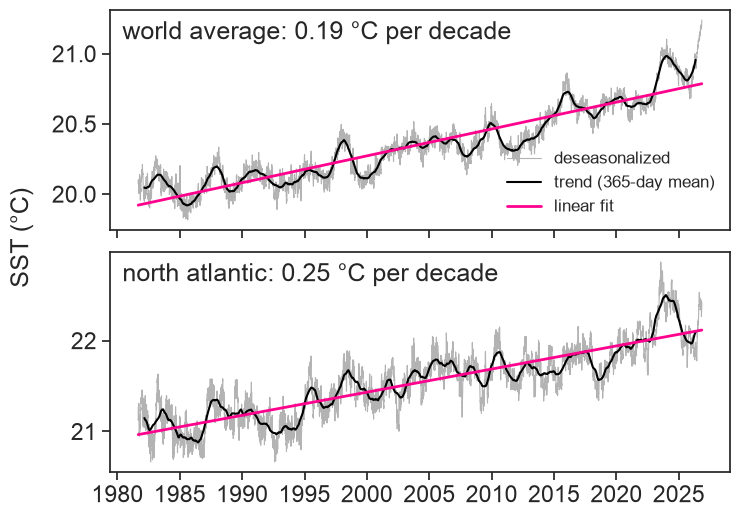

In [4]:
#| code-summary: "fit a line to the deseasonalized series"
def decimal_year(index):
    """convert dates to years with decimals, e.g. 2000-07-02 -> 2000.5"""
    return index.year + (index.day_of_year - 1) / 365.25

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
fig.subplots_adjust(hspace=0.1)
for axx, (name, df) in zip(ax, regions.items()):
    t = decimal_year(df.index)
    slope, intercept = np.polyfit(t, df['deseasonalized'], 1)
    axx.plot(df['deseasonalized'], color="0.7", lw=0.8, label="deseasonalized")
    axx.plot(df['trend'], color="black", label="trend (365-day mean)")
    axx.plot(df.index, intercept + slope * t, color="xkcd:hot pink", lw=2,
             label="linear fit")
    axx.text(0.02, 0.95, f"{name}: {10*slope:.2f} °C per decade", transform=axx.transAxes,
             ha='left', va='top')
ax[0].legend(frameon=False, loc="lower right", fontsize=12)
fig.text(0.0, 0.5, 'SST (°C)', va='center', rotation='vertical');

Over the whole record, the world average ocean surface has warmed by roughly 0.2 °C per decade, and the North Atlantic somewhat faster, about 0.25 °C per decade. Over 40+ years, that adds up to about 1 °C in the North Atlantic.

But look at the black trend line: it is not straight. A single line answers "how fast, on average, since 1982?", but not "how fast *now*?". Let's fit a line separately for three consecutive 15-year periods:

In [5]:
#| code-summary: "warming rate in each 15-year period"
periods = [("1982", "1996"), ("1997", "2011"), ("2012", "2026")]
rates = {}
for name, df in regions.items():
    rates[name] = {}
    for start, end in periods:
        segment = df.loc[start:end, 'deseasonalized']
        slope = np.polyfit(decimal_year(segment.index), segment, 1)[0]
        rates[name][f"{start}–{end}"] = 10 * slope
pd.DataFrame(rates).round(2).rename_axis("°C per decade")

,world average,north atlantic
°C per decade,,
1982–1996,0.07,0.12
1997–2011,0.12,0.20
2012–2026,0.36,0.47


The warming is accelerating. In both regions each period warms faster than the one before, and the most recent 15 years warm about four to five times faster than 1982–1996. Keep in mind that 15 years is not long: the unusually hot 2023–2024 pulls the slope of the last period up.

::: {.callout-warning}
## how sure are we about these numbers?

We are reporting slopes, but not their uncertainty, on purpose. The standard error that comes with an ordinary linear regression assumes that the deviations from the line are independent. Our residuals are anything but: their lag-1 autocorrelation is about 0.98, as you can check with `df_world['resid'].autocorr(1)`. Independent-looking data would give error bars that are far too narrow. Strongly autocorrelated deviations mean that we have many fewer *effectively independent* data points than days, a lesson straight from the [stationarity](../stationarity/autocorrelation.qmd) part.
:::

## "what is a *typical* annual oscillation in temperature?"

This is exactly what the seasonal component is: the average detrended year, averaged across all years in the record. Let's plot one year of it for each region.

world average: warmest around March 20, coldest around November 20
north atlantic: warmest around August 29, coldest around March 08


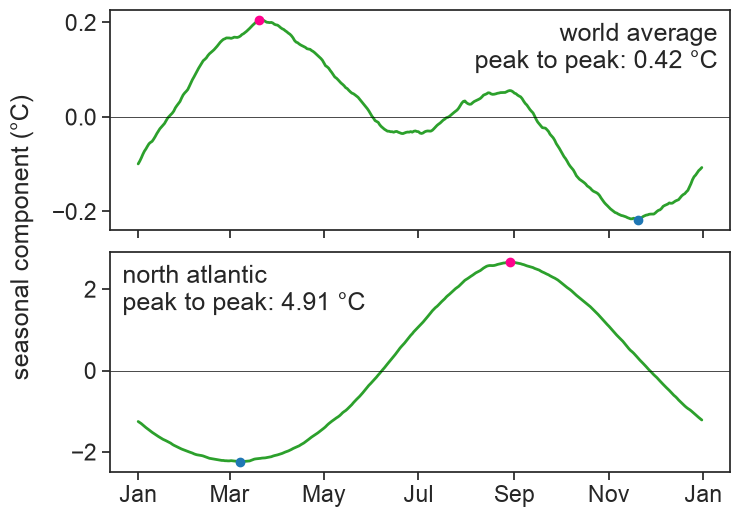

In [6]:
#| code-summary: "plot one year of the seasonal component"
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
fig.subplots_adjust(hspace=0.1)
for axx, (name, df) in zip(ax, regions.items()):
    seasonal = df.groupby('doy')['seasonal'].first().loc[1:365]
    # place day-of-year on a (non-leap) calendar year, only to label the x axis with months
    dates = pd.to_datetime("2001-01-01") + pd.to_timedelta(seasonal.index - 1, unit="D")
    axx.plot(dates, seasonal.values, color="tab:green", lw=2)
    axx.axhline(0, color="black", lw=0.5)
    hottest, coldest = dates[seasonal.values.argmax()], dates[seasonal.values.argmin()]
    axx.plot(hottest, seasonal.max(), 'o', color="xkcd:hot pink")
    axx.plot(coldest, seasonal.min(), 'o', color="tab:blue")
    x_text, align = (0.98, 'right') if name == "world average" else (0.02, 'left')  # avoid the curve
    axx.text(x_text, 0.95, f"{name}\npeak to peak: {seasonal.max() - seasonal.min():.2f} °C",
             transform=axx.transAxes, ha=align, va='top')
    print(f"{name}: warmest around {hottest:%B %d}, coldest around {coldest:%B %d}")
ax[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 3, 5, 7, 9, 11]))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.text(0.0, 0.5, 'seasonal component (°C)', va='center', rotation='vertical');

Two very different "typical years":

* **North Atlantic:** a typical year swings by almost 5 °C, coldest in early March and warmest at the end of August. Note that these are about two months *after* the winter and summer solstices (December 21 and June 21), when solar radiation is at its minimum and maximum. The ocean has a huge heat capacity, so it takes a long time to heat up and cool down.
* **World average:** the typical swing is about ten times smaller, around 0.4 °C. When one hemisphere has summer the other has winter, so the two largely cancel out. They don't cancel completely: the world average is warmest in March, at the end of the *southern* summer, because most of the world's ocean is in the Southern Hemisphere. The smaller bump in August is the northern summer.

The word *typical* matters. The seasonal component is an average over more than 40 years, and any single year deviates from it. Those deviations are the residual, and in the North Atlantic their standard deviation is only about a tenth of a degree, small compared with the seasonal swing.

## "how can I model processes such as this, where there are both a clear trend and a seasonal component?"

With the **additive model** of seasonal decomposition:

$$
\text{SST}(t) = T(t) + S(t) + e(t),
$$

and that is how we answered the first two questions: the trend $T(t)$ told us how fast the ocean is warming, and the seasonal component $S(t)$ told us what a typical year looks like. Each question was answered by looking at one component, with the others out of the way.

The additive model fits SST well because the size of the seasonal swing does not grow with the temperature itself. If it did, as in the airline passengers example in [theory](theory.ipynb), the multiplicative model $T(t)\times S(t)\times e(t)$ would be the better choice. And if the shape of the typical year itself changes slowly over the decades, [STL](stl-mstl.ipynb) can follow that change, whereas our decomposition assumes a single fixed seasonal pattern.

Whatever the method, the recipe is the same:

1. **choose the period.** Here it was obvious: one year, because Earth goes around the Sun. Decomposition methods require you to know the period beforehand.
2. **estimate the trend** by smoothing over one full period, so that the seasonal ups and downs average out.
3. **estimate the seasonal component** by averaging the detrended data at the same phase of every cycle (here, the same day of year).
4. **what is left is the residual.** Inspect it: it should have no trend and no remaining seasonal pattern. A good test for the latter is the autocorrelation at a lag of one period, which should be close to zero (see [from scratch](seasonal-decomposition-from-scratch.ipynb)).